# 02 · Comprensión del negocio y análisis exploratorio (EDA)


## 1. Librerías y carga
Trabajaremos con pandas, numpy, matplotlib y seaborn. Cada gráfico va seguido de interpretación; no basta con dibujar.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
base = next((p for p in [Path.cwd()/"Base_de_datos.csv", Path.cwd().parent/"Base_de_datos.csv"] if p.exists()), None)
if base is None:
    raise FileNotFoundError("Abre el proyecto desde su carpeta raíz")
raw = pd.read_csv(base, encoding="utf-8-sig", low_memory=False)
print("Dimensiones:",raw.shape)
display(raw.head(5))

Dimensiones: (10763, 23)


,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,45664.611528,1852560.0,12,32,Empleado,3500000,1000000,128650,95.227787,795.0,0,2,0.0,0.0,NaN,NaN,0,0,0,916148.0,Creciente,1
1,4,45666.471389,3181080.0,6,34,Empleado,5000000,2000000,441817,95.227787,796.0,0,7,0.0,0.0,NaN,NaN,0,0,0,4473774.0,Creciente,1
2,9,45652.786771,670200.0,5,34,Independiente,5000000,2000000,108632,95.227787,727.0,5,0,0.0,274561.0,274561.0,NaN,2,0,1,NaN,NaN,1
3,9,45630.597801,506806.8,2,25,Independiente,3000000,900000,199684,95.227787,864.0,8,1,0.0,27564.0,27564.0,NaN,1,0,6,NaN,NaN,1
4,4,45777.779132,999780.0,10,26,Empleado,2000000,600000,92509,95.227787,771.0,0,3,0.0,0.0,NaN,NaN,0,0,0,61000.0,Creciente,1


## 2. Caracterización del esquema
**Numéricas:** montos, plazos, edades, puntajes y conteos. **Categóricas nominales:** tipo de crédito y condición laboral. **Ordinal posible:** tendencia de ingresos (creciente/estable/decreciente, aunque no asumimos orden sin justificación). **Dicotómica:** `Pago_atiempo`. **Fecha:** `fecha_prestamo` convertida desde serial de Excel.
Algunas columnas numéricas llegan como texto mixto y por eso se corregirán.

In [2]:
schema = pd.DataFrame({"columna": raw.columns, "tipo_leido": raw.dtypes.astype(str).values,
                       "nulos": raw.isna().sum().values,
                       "nulos_pct": (raw.isna().mean()*100).round(2).values,
                       "unicos": raw.nunique(dropna=False).values})
display(schema)
print("Duplicados exactos:",raw.duplicated().sum())
print("Nulos por variable (mayores a 0):")
display(schema.loc[schema.nulos > 0].sort_values("nulos",ascending=False))

,columna,tipo_leido,nulos,nulos_pct,unicos
0,tipo_credito,int64,0,0.00,6
1,fecha_prestamo,float64,0,0.00,10758
2,capital_prestado,float64,0,0.00,7306
3,plazo_meses,int64,0,0.00,18
4,edad_cliente,int64,0,0.00,54
5,tipo_laboral,object,0,0.00,2
6,salario_cliente,int64,0,0.00,1385
7,total_otros_prestamos,int64,0,0.00,1538
8,cuota_pactada,int64,0,0.00,9836
9,puntaje,float64,0,0.00,248


Duplicados exactos: 0
Nulos por variable (mayores a 0):


,columna,tipo_leido,nulos,nulos_pct,unicos
21,tendencia_ingresos,object,2932,27.24,47
20,promedio_ingresos_datacredito,float64,2930,27.22,5310
16,saldo_mora_codeudor,float64,590,5.48,5
15,saldo_principal,float64,405,3.76,8648
13,saldo_mora,float64,156,1.45,56
14,saldo_total,float64,156,1.45,8859
10,puntaje_datacredito,float64,6,0.06,316


## 3. Unificar nulos y corregir tipos
No se eliminan filas automáticamente. Los valores faltantes se dejarán como `NaN` para imputarlos dentro del pipeline de entrenamiento sin fuga de información. Los valores de `tendencia_ingresos` fuera de las tres categorías conocidas pasan a `Sin dato`.

In [3]:
df = raw.copy().replace(r"^\s*$", np.nan, regex=True)
for c in ["edad_cliente","salario_cliente","puntaje","puntaje_datacredito","capital_prestado",
          "plazo_meses","cuota_pactada","promedio_ingresos_datacredito"]:
    df[c] = pd.to_numeric(df[c],errors="coerce")
excel_date = pd.to_numeric(df["fecha_prestamo"],errors="coerce")
df["fecha_prestamo_convertida"] = pd.to_datetime(excel_date,unit="D",origin="1899-12-30",errors="coerce")
trend = df["tendencia_ingresos"].astype("string").str.strip().str.title()
df["tendencia_ingresos_limpia"] = trend.where(trend.isin(["Creciente","Estable","Decreciente"]),"Sin dato").fillna("Sin dato")
print("Fechas:",df["fecha_prestamo_convertida"].min(),"a",df["fecha_prestamo_convertida"].max())
print("Tendencias originales:")
display(raw["tendencia_ingresos"].value_counts(dropna=False).head(12))
print("Tendencias normalizadas:")
display(df["tendencia_ingresos_limpia"].value_counts(dropna=False))

Fechas: 2024-11-26 09:17:03.999999857 a 2026-04-26 18:43:51.999999821
Tendencias originales:


tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
158042            1
168750            1
3978              1
-28589            1
Name: count, dtype: int64

Tendencias normalizadas:


tendencia_ingresos_limpia
Creciente      5294
Sin dato       2990
Decreciente    1291
Estable        1188
Name: count, dtype: Int64

### Hallazgos de tipos y calidad
La fecha de Excel se convierte a calendario. `edad_cliente` tiene un máximo de 123, `salario_cliente` llega hasta 22.000.000.000 y `puntaje_datacredito` incluye negativos. Estas inconsistencias se convierten en nulos y se imputan únicamente con los datos de entrenamiento. No se usa `saldo_mora`, `saldo_total`, `saldo_principal` y `saldo_mora_codeudor` sin validar primero que existían al momento de la solicitud.

In [4]:
audit = pd.DataFrame({
    "regla": ["Edad fuera de 18-100", "Salario <=0 o >100 millones", "Puntaje fuera de 0-100",
             "Datacredito fuera de 1-1000", "Tendencia no válida", "Fechas sin conversión"],
    "casos": [int((~df["edad_cliente"].between(18,100)).sum()),
              int((~df["salario_cliente"].between(1,100_000_000)).sum()),
              int((~df["puntaje"].between(0,100)).sum()),
              int((~df["puntaje_datacredito"].between(1,1000)).sum()),
              int((~trend.isin(["Creciente","Estable","Decreciente"])).sum()),
              int(df["fecha_prestamo_convertida"].isna().sum())]
})
display(audit)

,regla,casos
0,Edad fuera de 18-100,150
1,Salario <=0 o >100 millones,98
2,Puntaje fuera de 0-100,135
3,Datacredito fuera de 1-1000,152
4,Tendencia no válida,2990
5,Fechas sin conversión,0


## 4. Análisis univariable: variable objetivo
La mayoría de registros corresponde a pagos puntuales. 

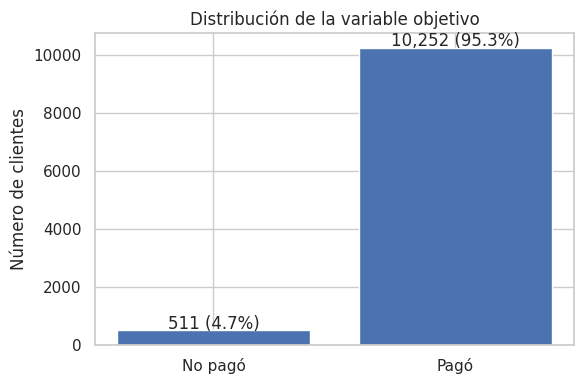

In [5]:
counts = raw["Pago_atiempo"].value_counts().reindex([0,1],fill_value=0)
fig, ax=plt.subplots(figsize=(6,4))
ax.bar(["No pagó", "Pagó"], counts.values)
for i,v in enumerate(counts): ax.text(i,v+50,f"{v:,} ({v/len(raw):.1%})",ha="center")
ax.set_title("Distribución de la variable objetivo")
ax.set_ylabel("Número de clientes")
plt.tight_layout(); plt.show()

## 5. Análisis univariable: variables numéricas
Para numéricas veremos `describe`, mediana, rango, cuartiles, IQR, desviación, asimetría y curtosis; los histogramas permiten detectar concentración y colas largas, y los boxplots resaltan valores extremos.

In [6]:
numericas=["edad_cliente","capital_prestado","plazo_meses","salario_cliente","cuota_pactada",
           "puntaje","puntaje_datacredito","promedio_ingresos_datacredito"]
stats=df[numericas].describe(percentiles=[.25,.5,.75]).T
stats["iqr"]=stats["75%"]-stats["25%"]
stats["varianza"]=df[numericas].var()
stats["asimetria"]=df[numericas].skew()
stats["curtosis"]=df[numericas].kurt()
display(stats.round(2))

,count,mean,std,min,25%,50%,75%,max,iqr,varianza,asimetria,curtosis
edad_cliente,10763.0,43.95,1.506000e+01,19.00,33.00,42.00,53.00,1.230000e+02,20.0,2.268300e+02,1.93,7.87
capital_prestado,10763.0,2434315.00,1.909643e+06,360000.00,1224831.00,1921920.00,3084840.00,4.144415e+07,1860009.0,3.646735e+12,3.72,35.32
plazo_meses,10763.0,10.58,6.630000e+00,2.00,6.00,10.00,12.00,9.000000e+01,6.0,4.398000e+01,2.46,7.78
salario_cliente,10763.0,17216431.46,3.554767e+08,0.00,2000000.00,3000000.00,4875808.00,2.200000e+10,2875808.0,1.263637e+17,43.78,2211.23
cuota_pactada,10763.0,243617.41,2.104937e+05,23944.00,121041.50,182863.00,287833.50,3.816752e+06,166792.0,4.430760e+10,3.79,26.65
puntaje,10763.0,91.17,1.647000e+01,-38.01,95.23,95.23,95.23,9.523000e+01,0.0,2.711100e+02,-4.87,24.08
puntaje_datacredito,10757.0,780.79,1.048800e+02,-7.00,757.00,791.00,825.00,9.990000e+02,68.0,1.099940e+04,-5.64,39.44
promedio_ingresos_datacredito,7833.0,2005156.81,2.144116e+06,0.00,925157.00,1204496.00,2231859.00,3.810658e+07,1306702.0,4.597234e+12,4.28,32.77


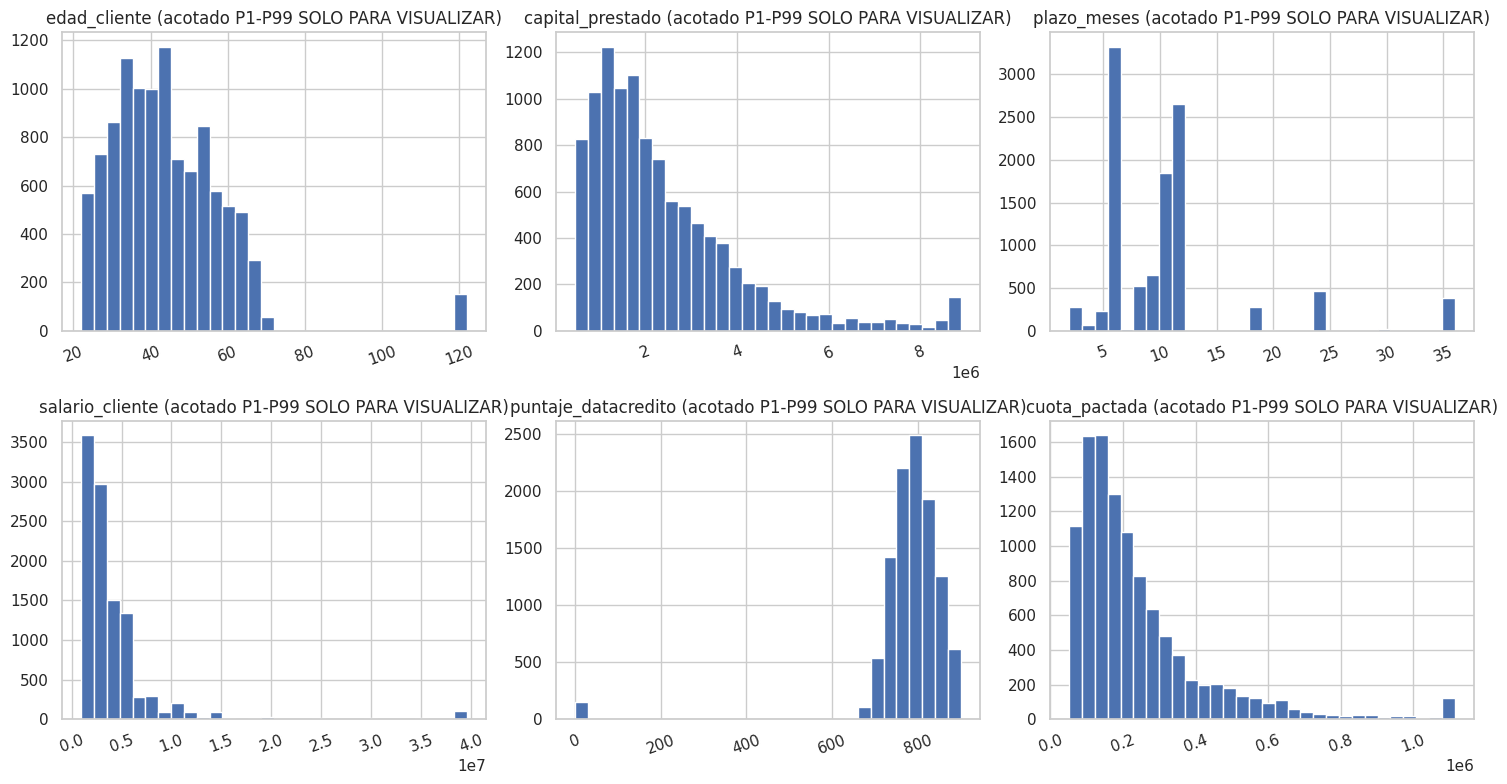

In [7]:
fig, axes=plt.subplots(2,3,figsize=(15,8))
for ax,col in zip(axes.flat,["edad_cliente","capital_prestado","plazo_meses","salario_cliente","puntaje_datacredito","cuota_pactada"]):
    vals=df[col].dropna()
    lower, upper=vals.quantile([.01,.99])
    ax.hist(vals.clip(lower,upper),bins=30)
    ax.set_title(f"{col} (acotado P1-P99 SOLO PARA VISUALIZAR)")
for ax in axes.flat: ax.tick_params(axis="x",labelrotation=20)
plt.tight_layout(); plt.show()

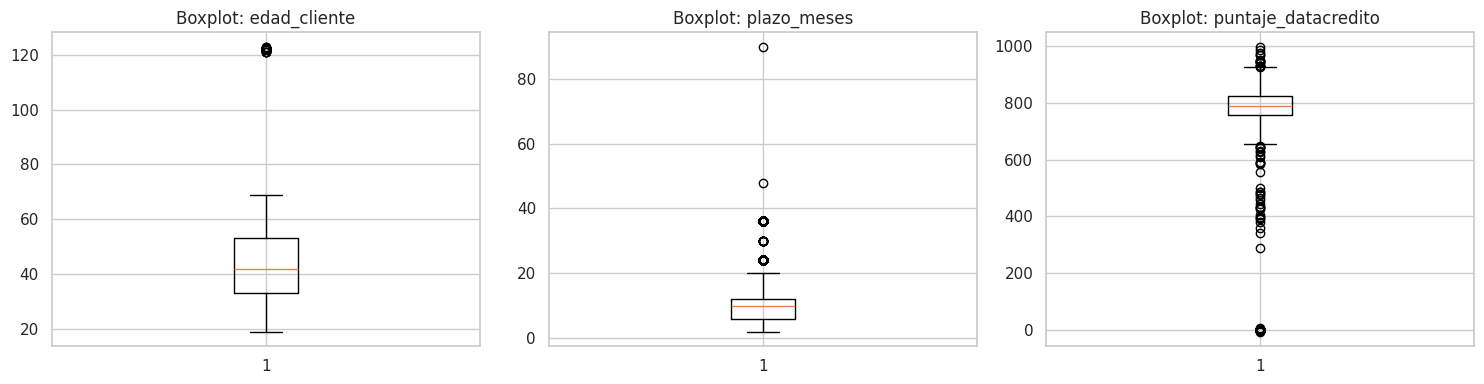

In [8]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,col in zip(axes,["edad_cliente","plazo_meses","puntaje_datacredito"]):
    ax.boxplot(df[col].dropna(), orientation="vertical")
    ax.set_title(f"Boxplot: {col}")
plt.tight_layout(); plt.show()

## 6. Análisis univariable: categóricas
Revisamos `tipo_credito`, `tipo_laboral`, `tendencia_ingresos` (limpia) y sus frecuencias. Un código de tipo de crédito no representa una magnitud, por eso es categórico incluso si contiene números.

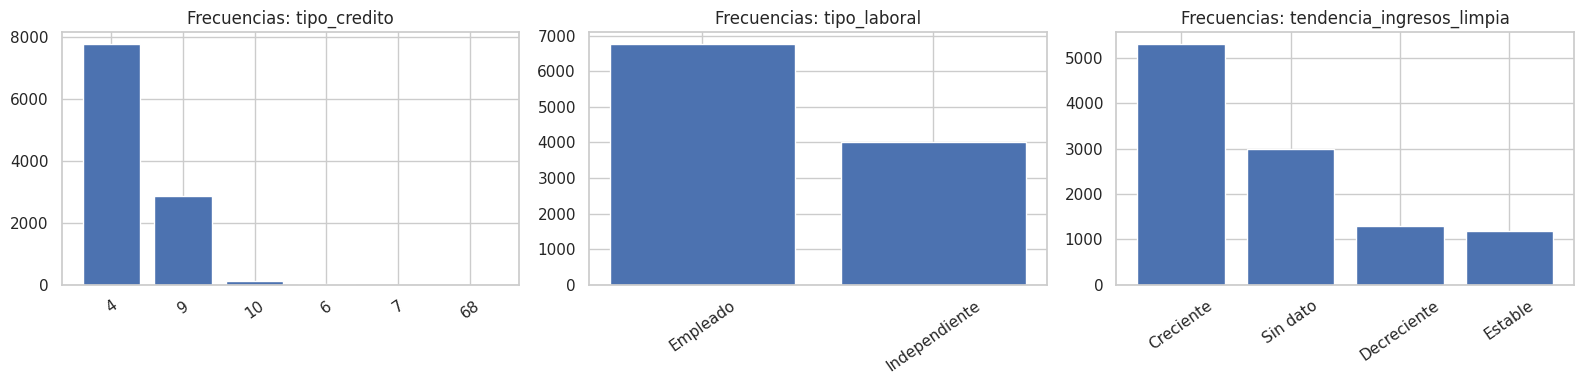

In [9]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,col in zip(axes,["tipo_credito","tipo_laboral","tendencia_ingresos_limpia"]):
    series=df[col].fillna("Sin dato").astype(str)
    counts=series.value_counts().head(10)
    ax.bar(counts.index, counts.values)
    ax.set_title(f"Frecuencias: {col}"); ax.tick_params(axis="x",rotation=35)
plt.tight_layout(); plt.show()

## 7. Análisis bivariable: cada factor frente al objetivo
La tasa de riesgo es la proporción de `Pago_atiempo=0`. Compararemos variables categóricas y cuantitativas con cuidado: una relación observada no demuestra causalidad.

In [10]:
df["riesgo"] = (df["Pago_atiempo"]==0).astype(int)
for col in ["tipo_laboral","tipo_credito","tendencia_ingresos_limpia"]:
    resumen=df.groupby(col,dropna=False)["riesgo"].agg(casos="size", tasa_incumplimiento="mean")
    resumen["tasa_incumplimiento_pct"]=(100*resumen["tasa_incumplimiento"]).round(2)
    print(); print(col); display(resumen.sort_values("casos",ascending=False).head(12))


tipo_laboral


,casos,tasa_incumplimiento,tasa_incumplimiento_pct
tipo_laboral,,,
Empleado,6754,0.042938,4.29
Independiente,4009,0.055126,5.51



tipo_credito


,casos,tasa_incumplimiento,tasa_incumplimiento_pct
tipo_credito,,,
4,7747,0.046857,4.69
9,2876,0.047288,4.73
10,116,0.025862,2.59
6,21,0.428571,42.86
7,2,0.000000,0.00
68,1,0.000000,0.00



tendencia_ingresos_limpia


,casos,tasa_incumplimiento,tasa_incumplimiento_pct
tendencia_ingresos_limpia,,,
Creciente,5294,0.039101,3.91
Sin dato,2990,0.056187,5.62
Decreciente,1291,0.062742,6.27
Estable,1188,0.046296,4.63


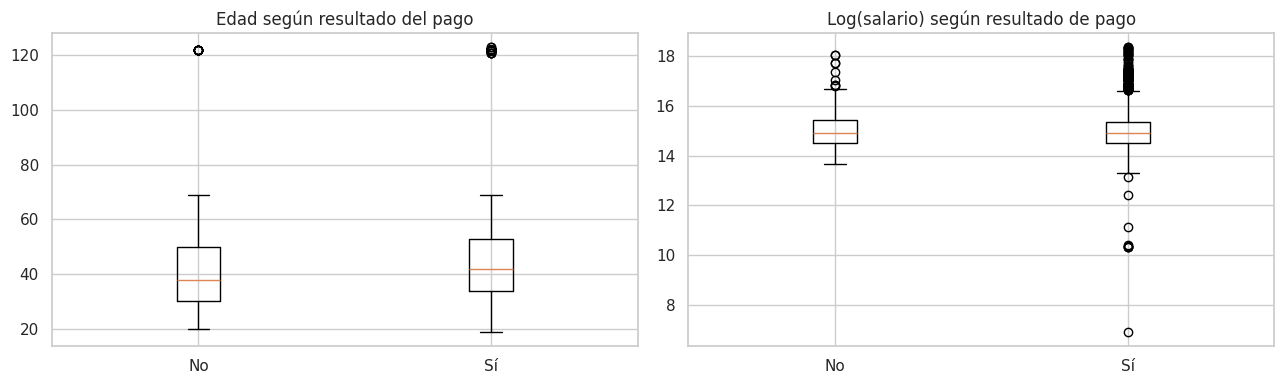

In [11]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].boxplot([df.loc[df.Pago_atiempo==g,"edad_cliente"].dropna() for g in [0,1]],tick_labels=["No", "Sí"])
axes[0].set_title("Edad según resultado del pago")
valid_salary=df.loc[df["salario_cliente"].between(1,100_000_000)].copy()
valid_salary["log_salario"] = np.log1p(valid_salary["salario_cliente"])
axes[1].boxplot([valid_salary.loc[valid_salary.Pago_atiempo==g,"log_salario"].dropna() for g in [0,1]],tick_labels=["No", "Sí"])
axes[1].set_title("Log(salario) según resultado de pago")
plt.tight_layout(); plt.show()

**Interpretación:** los grupos con muy pocos casos pueden mostrar tasas extremas que no son estadísticamente confiables. Al comparar montos, la transformación logarítmica permite visualizar sin que un salario gigantesco tape los demás registros.

## 8. Análisis multivariable
La correlación estudia relaciones lineales entre variables numéricas. El *pairplot* se hace sobre muestra reducida para evitar gráficas gigantes. No incluimos saldos actuales en la etapa de entrenamiento hasta verificar disponibilidad temporal.

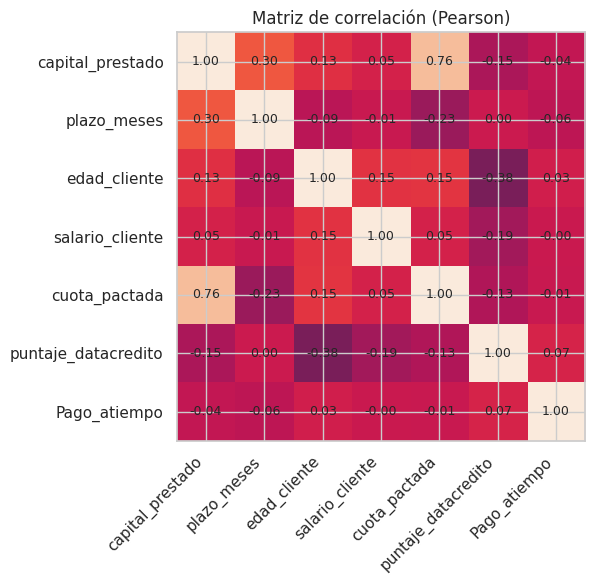

In [12]:
campos=["capital_prestado","plazo_meses","edad_cliente","salario_cliente", "cuota_pactada",
        "puntaje_datacredito","Pago_atiempo"]
cor=df[campos].corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(9,6))
ax.imshow(cor.to_numpy(),vmin=-1,vmax=1)
ax.set_xticks(range(len(cor.columns)), labels=cor.columns, rotation=45, ha="right")
ax.set_yticks(range(len(cor.index)), labels=cor.index)
for row in range(len(cor)):
    for col in range(len(cor)):
        ax.text(col,row,f"{cor.iat[row,col]:.2f}",ha="center",va="center",fontsize=9)
ax.set_title("Matriz de correlación (Pearson)")
plt.tight_layout();plt.show()

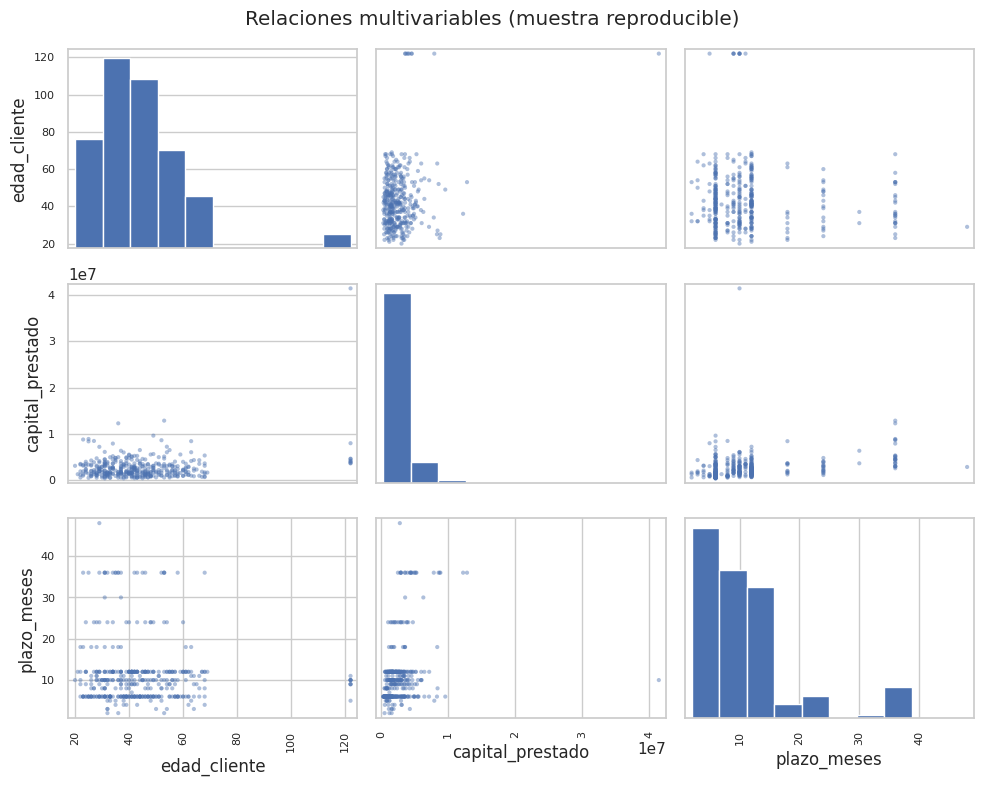

In [13]:
sample=df[["edad_cliente","capital_prestado","plazo_meses","Pago_atiempo"]].dropna().sample(n=min(400,len(df)),random_state=42)
from pandas.plotting import scatter_matrix
axes=scatter_matrix(sample[["edad_cliente","capital_prestado","plazo_meses"]],figsize=(10,8),diagonal="hist",alpha=.45)
plt.suptitle("Relaciones multivariables (muestra reproducible)")
plt.tight_layout(); plt.show()

## 9. Reglas 
1. Convertir a nulos edades fuera de 18-100, salarios `<=0` o mayores a 100 millones, puntajes negativos o fuera de escala. 2. Uniformar textos de categorías y fechas de Excel. 3. Imputar nulos **después** de separar train/test y aprender las medianas solo en entrenamiento. 4. Convertir nominales con OneHotEncoder. 5. Crear ratios cuota/salario y capital/salario. 6. Excluir saldos posteriores por potencial fuga de información. 7. Partición estratificada porque la clase minoritaria es aproximadamente 4,75 %.

In [14]:
from IPython.display import Markdown
total=len(df); bad=int((df.Pago_atiempo==0).sum()); ok=total-bad
print(f"Registros analizados: {total:,}; pagaron a tiempo: {ok:,}; no pagaron: {bad:,} ({bad/total:.2%})")
print("Variables que no usaremos sin verificar su fecha: saldo_mora, saldo_total, saldo_principal, saldo_mora_codeudor")
print("Siguiente etapa: python -m mlops_pipeline.ft_engineering")

Registros analizados: 10,763; pagaron a tiempo: 10,252; no pagaron: 511 (4.75%)
Variables que no usaremos sin verificar su fecha: saldo_mora, saldo_total, saldo_principal, saldo_mora_codeudor
Siguiente etapa: python -m mlops_pipeline.ft_engineering


## 10. Conclusiones del EDA
- Es un problema de **clasificación binaria desbalanceada**; se optimizo métricas relevantes para incumplimiento.
- Hay errores y faltantes, pero no es recomendable eliminar filas sin investigar: se perdería información de la clase minoritaria.
- Las fechas y categorías requieren normalización y hay montos extremos que distorsionan gráficos.
- La mayor amenaza metodológica es el *data leakage*: variables de mora presentes después del desembolso no deben participar en una predicción prospectiva.
- Estas observaciones se implementan de forma reproducible en `ft_engineering.py` y se comprobarán en un test separado.

